In [1]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
from skimage.feature import local_binary_pattern
import warnings
import mahotas
warnings.filterwarnings("ignore")

In [2]:
GROUP = "C5"
DTYPE="HRLK"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C5_10,28,"[DATA/TRAINING/C5/C5_10/IMG_7706.HEIC, DATA/TR..."
1,C5_11,30,"[DATA/TRAINING/C5/C5_11/IMG_7780.HEIC, DATA/TR..."
2,C5_12,26,"[DATA/TRAINING/C5/C5_12/IMG_7858.HEIC, DATA/TR..."
3,C5_13,27,"[DATA/TRAINING/C5/C5_13/IMG_7917.HEIC, DATA/TR..."
4,C5_14,27,"[DATA/TRAINING/C5/C5_14/IMG_7981.HEIC, DATA/TR..."
5,C5_15,28,"[DATA/TRAINING/C5/C5_15/IMG_8046.jpg, DATA/TRA..."
6,C5_16,25,"[DATA/TRAINING/C5/C5_16/IMG_8109.HEIC, DATA/TR..."


In [3]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [4]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [5]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

In [6]:
def read_image(pic_path):
    ext = pic_path.split(".")[1]
    if ext=="HEIC":
        return read_imgHEIC(pic_path)
    else:
        img=cv2.imread(pic_path)
        return img

Text(0.5, 1.0, '16% IMG_8124.HEIC')

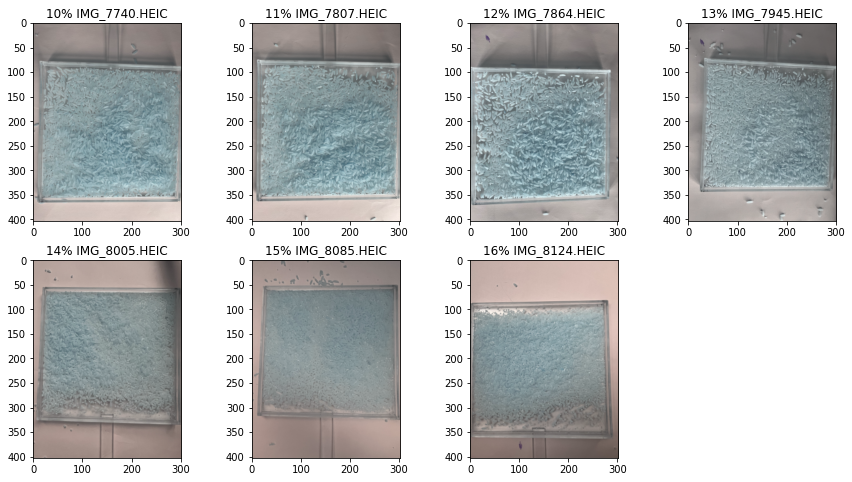

In [7]:
fig=plt.figure(figsize=(15, 8)) 
ax1 = fig.add_subplot(2,4,1); path_image= random.randint(0, 25)
image = read_image(data_path[0][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10% " + data_path[0][path_image].split("/")[4])
ax2 = fig.add_subplot(2,4,2); path_image= random.randint(0, 25)
image = read_image(data_path[1][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11% "+ data_path[1][path_image].split("/")[4])
ax3 = fig.add_subplot(2,4,3); path_image= random.randint(0, 25)
image = read_image(data_path[2][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12% "+ data_path[2][path_image].split("/")[4])
ax4 = fig.add_subplot(2,4,4); path_image= random.randint(0, 25)
image = read_image(data_path[3][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13% "+ data_path[3][path_image].split("/")[4])
ax5 = fig.add_subplot(2,4,5); path_image= random.randint(0, 25)
image = read_image(data_path[4][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14% "+ data_path[4][path_image].split("/")[4])
ax6 = fig.add_subplot(2,4,6); path_image= random.randint(0, 25)
image = read_image(data_path[5][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15% "+ data_path[5][path_image].split("/")[4])
ax7 = fig.add_subplot(2,4,7); path_image= random.randint(0, 25)
image = read_image(data_path[6][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16% "+ data_path[6][path_image].split("/")[4])

In [124]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
#bins=44; #width=2024; height=3032; 
scale=20
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

        haralick = mahotas.features.haralick(gray).ravel()
        arr_img_hist.append(haralick)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [125]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,9,...,48,49,50,51,scale,height,width,channels,IMAGENAME,HUMIDITY
0,0.000685,68.709655,0.960580,871.505939,0.319655,310.216002,3417.314101,7.868291,11.270587,0.000521,...,0.000349,4.164182,-0.277062,0.988908,20,806,604,3,IMG_7706.HEIC,10
1,0.000740,59.848932,0.965652,871.208529,0.329193,307.424079,3424.985184,7.847567,11.187744,0.000528,...,0.000366,4.050823,-0.290843,0.990728,20,806,604,3,IMG_7709.HEIC,10
2,0.000728,64.022001,0.963775,883.661485,0.330554,305.629444,3470.623938,7.862697,11.221462,0.000520,...,0.000346,4.125347,-0.282591,0.989706,20,806,604,3,IMG_7710.HEIC,10
3,0.000698,80.434002,0.950904,819.153059,0.306877,313.553817,3196.178234,7.828212,11.341513,0.000471,...,0.000319,4.244450,-0.261819,0.986055,20,806,604,3,IMG_7713.HEIC,10
4,0.000754,71.233925,0.953012,758.008093,0.311610,313.576283,2960.798448,7.783628,11.255848,0.000480,...,0.000323,4.200850,-0.262251,0.985798,20,806,604,3,IMG_7714.HEIC,10
5,0.000895,65.387220,0.947938,627.980132,0.319450,312.291141,2446.533308,7.629147,11.053755,0.000495,...,0.000336,4.139751,-0.255557,0.983189,20,806,604,3,IMG_7718.HEIC,10
6,0.000655,87.778658,0.947491,835.843733,0.300404,311.058232,3255.596274,7.842930,11.416877,0.000454,...,0.000315,4.254761,-0.261804,0.986168,20,806,604,3,IMG_7719.HEIC,10
7,0.000785,78.976186,0.945916,730.130057,0.313559,312.491105,2841.544042,7.725088,11.218023,0.000480,...,0.000333,4.184283,-0.261225,0.985185,20,806,604,3,IMG_7721.HEIC,10
8,0.000886,66.203313,0.952316,694.194300,0.319692,305.133929,2710.573885,7.680898,11.107271,0.000491,...,0.000339,4.127466,-0.263992,0.985397,20,806,604,3,IMG_7723.HEIC,10
9,0.001091,56.926375,0.952594,600.407849,0.338288,308.035326,2344.705020,7.560424,10.874731,0.000530,...,0.000358,4.061163,-0.260999,0.983799,20,806,604,3,IMG_7725.HEIC,10


# Classification

In [126]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-6]
#X

In [127]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [128]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [129]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

#### Random Forest Classifier

In [130]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [131]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.950000,0.964286,0.952381,0.958296,HRLK,C5,RF_C,20,806,604,3
1,2,0.789474,0.821429,0.785714,0.803175,HRLK,C5,RF_C,20,806,604,3
2,3,0.789474,0.833333,0.785714,0.808824,HRLK,C5,RF_C,20,806,604,3
3,4,0.789474,0.871429,0.809524,0.839336,HRLK,C5,RF_C,20,806,604,3
4,5,0.947368,0.964286,0.952381,0.958296,HRLK,C5,RF_C,20,806,604,3
5,6,0.842105,0.869048,0.857143,0.863054,HRLK,C5,RF_C,20,806,604,3
6,7,1.000000,1.000000,1.000000,1.000000,HRLK,C5,RF_C,20,806,604,3
7,8,1.000000,1.000000,1.000000,1.000000,HRLK,C5,RF_C,20,806,604,3
8,9,0.947368,0.964286,0.952381,0.958296,HRLK,C5,RF_C,20,806,604,3
9,10,0.842105,0.880952,0.857143,0.868885,HRLK,C5,RF_C,20,806,604,3


In [132]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,HRLK,C5,RF_C,0.889737,0.895238,0.905816,0.916905


### MLP Classifier

In [133]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [134]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [135]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.950000,0.964286,0.928571,0.946092,HRLK,C5,MLP_C,20,806,604,3
1,2,0.894737,0.904762,0.904762,0.904762,HRLK,C5,MLP_C,20,806,604,3
2,3,0.736842,0.750000,0.761905,0.755906,HRLK,C5,MLP_C,20,806,604,3
3,4,0.947368,0.964286,0.952381,0.958296,HRLK,C5,MLP_C,20,806,604,3
4,5,0.842105,0.869048,0.857143,0.863054,HRLK,C5,MLP_C,20,806,604,3
5,6,0.894737,0.916667,0.904762,0.910675,HRLK,C5,MLP_C,20,806,604,3
6,7,0.789474,0.857143,0.809524,0.832653,HRLK,C5,MLP_C,20,806,604,3
7,8,1.000000,1.000000,1.000000,1.000000,HRLK,C5,MLP_C,20,806,604,3
8,9,0.947368,0.964286,0.928571,0.946092,HRLK,C5,MLP_C,20,806,604,3
9,10,0.894737,0.916667,0.904762,0.910675,HRLK,C5,MLP_C,20,806,604,3


In [136]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,HRLK,C5,MLP_C,0.889737,0.895238,0.902821,0.910714


### XGBoost Classifier

In [137]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [138]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.800000,0.859524,0.809524,0.833775,HRLK,C5,XGB_C,20,806,604,3
1,2,0.789474,0.821429,0.809524,0.815433,HRLK,C5,XGB_C,20,806,604,3
2,3,0.894737,0.942857,0.904762,0.923417,HRLK,C5,XGB_C,20,806,604,3
3,4,0.789474,0.714286,0.761905,0.737327,HRLK,C5,XGB_C,20,806,604,3
4,5,0.789474,0.859524,0.785714,0.820963,HRLK,C5,XGB_C,20,806,604,3
5,6,0.894737,0.916667,0.904762,0.910675,HRLK,C5,XGB_C,20,806,604,3
6,7,0.842105,0.857143,0.857143,0.857143,HRLK,C5,XGB_C,20,806,604,3
7,8,1.000000,1.000000,1.000000,1.000000,HRLK,C5,XGB_C,20,806,604,3
8,9,0.736842,0.761905,0.738095,0.749811,HRLK,C5,XGB_C,20,806,604,3
9,10,0.894737,0.928571,0.880952,0.904135,HRLK,C5,XGB_C,20,806,604,3


In [139]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,HRLK,C5,XGB_C,0.843158,0.845238,0.855268,0.86619


# External validation

In [140]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C5_10,5,"[DATA/TEST/C5/C5_10/IMG_7696.HEIC, DATA/TEST/C..."
1,C5_11,5,"[DATA/TEST/C5/C5_11/IMG_7770.HEIC, DATA/TEST/C..."
2,C5_12,5,"[DATA/TEST/C5/C5_12/IMG_7847.HEIC, DATA/TEST/C..."
3,C5_13,5,"[DATA/TEST/C5/C5_13/IMG_7908.HEIC, DATA/TEST/C..."
4,C5_14,5,"[DATA/TEST/C5/C5_14/IMG_7971.HEIC, DATA/TEST/C..."
5,C5_15,5,"[DATA/TEST/C5/C5_15/IMG_8037.DNG, DATA/TEST/C5..."
6,C5_16,5,"[DATA/TEST/C5/C5_16/IMG._8128.HEIC, DATA/TEST/..."


In [141]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [142]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        haralick = mahotas.features.haralick(gray).ravel()
        arr_img_hist.append(haralick)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [143]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,9,...,48,49,50,51,scale,height,width,channels,IMAGENAME,HUMIDITY
0,0.000678,71.733358,0.957362,841.183880,0.313218,311.952452,3293.002161,7.861285,11.306281,0.000487,...,0.000323,4.214150,-0.269348,0.987623,20,806,604,3,IMG_7696.HEIC,10
1,0.000757,63.518057,0.960470,803.423331,0.322923,311.089406,3150.175265,7.781362,11.146427,0.000511,...,0.000344,4.126263,-0.275253,0.988088,20,806,604,3,IMG_7698.HEIC,10
2,0.000656,70.297549,0.962291,932.111743,0.312637,312.369867,3658.149422,7.907947,11.349705,0.000490,...,0.000327,4.197952,-0.275828,0.988972,20,806,604,3,IMG_7701.HEIC,10
3,0.000679,66.609350,0.962235,881.889823,0.321079,310.566891,3460.949944,7.885831,11.280343,0.000506,...,0.000336,4.163447,-0.277905,0.989145,20,806,604,3,IMG_7702.HEIC,10
4,0.000681,70.150307,0.960107,879.221894,0.322046,313.329527,3446.737270,7.885066,11.287131,0.000501,...,0.000338,4.160486,-0.279276,0.989342,20,806,604,3,IMG_7704.HEIC,10
0,0.000634,78.370783,0.960967,1003.902522,0.316208,308.247911,3937.239305,7.984169,11.468615,0.000482,...,0.000334,4.175886,-0.285796,0.990805,20,806,604,3,IMG_7770.HEIC,11
1,0.000671,75.170479,0.961702,981.386938,0.315788,308.701661,3850.377273,7.942608,11.411125,0.000485,...,0.000341,4.136756,-0.286885,0.990731,20,806,604,3,IMG_7771.HEIC,11
2,0.000725,69.790512,0.963782,963.465105,0.324967,312.047650,3784.069910,7.918147,11.338574,0.000498,...,0.000338,4.157024,-0.283568,0.990161,20,806,604,3,IMG_7775.HEIC,11
3,0.000709,71.405113,0.960498,903.824605,0.311602,304.547428,3543.893307,7.885037,11.366757,0.000478,...,0.000332,4.160358,-0.277505,0.989100,20,806,604,3,IMG_7776.HEIC,11
4,0.000679,73.747355,0.960906,943.209615,0.315253,309.280039,3699.091107,7.931964,11.405412,0.000481,...,0.000338,4.140520,-0.285184,0.990449,20,806,604,3,IMG_7779.HEIC,11


In [144]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [145]:
X_test = dtFeaturesTest.values[:, :-6]
#X_test

In [146]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [147]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [148]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.80      0.80      0.80         5
     Class 1       0.83      1.00      0.91         5
     Class 2       0.56      1.00      0.71         5
     Class 3       1.00      0.20      0.33         5
     Class 4       1.00      0.80      0.89         5
     Class 5       1.00      1.00      1.00         5
     Class 6       1.00      1.00      1.00         5

    accuracy                           0.83        35
   macro avg       0.88      0.83      0.81        35
weighted avg       0.88      0.83      0.81        35



## MLP

In [149]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [150]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      0.80      0.89         5
     Class 1       0.71      1.00      0.83         5
     Class 2       0.62      1.00      0.77         5
     Class 3       1.00      0.20      0.33         5
     Class 4       1.00      0.80      0.89         5
     Class 5       1.00      1.00      1.00         5
     Class 6       0.83      1.00      0.91         5

    accuracy                           0.83        35
   macro avg       0.88      0.83      0.80        35
weighted avg       0.88      0.83      0.80        35



## XGBC

In [151]:
y_pred = modelXGBC.predict(X_test_scale) 

In [152]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      0.80      0.89         5
     Class 1       0.83      1.00      0.91         5
     Class 2       0.56      1.00      0.71         5
     Class 3       0.00      0.00      0.00         5
     Class 4       0.83      1.00      0.91         5
     Class 5       0.71      1.00      0.83         5
     Class 6       1.00      0.60      0.75         5

    accuracy                           0.77        35
   macro avg       0.71      0.77      0.71        35
weighted avg       0.71      0.77      0.71        35

